# 03 - Modelos predictivos y explicabilidad (Avance 3)

**Proyecto:** Estacionalidad y composición del delito en la Región de Valparaíso (EIN092B)

**Pregunta predictiva:** ¿cuántos casos policiales tendrá cada familia de delito en un mes dado, y cuáles aumentarán respecto al mismo mes del año anterior?

- **Tarea:** regresión. **y** = casos mensuales de una familia.
- **Cómo se modela y:** las familias tienen escalas muy distintas (Otros delitos ~6.000 casos al mes, Armas ~150). Por eso el modelo predice un **índice relativo** = casos del mes / promedio de los 12 meses anteriores de esa familia (1,0 = mes típico, como el 100 del heatmap del EDA). La predicción en casos se recupera multiplicando por ese promedio, y todas las métricas se calculan en casos.
- **X:** familia, mes anterior y mismo mes del año anterior (ambos relativos al promedio de 12 meses), mes del año (seno y coseno), tendencia e indicador de pandemia (mar-2020 a dic-2021). Todas usan solo meses anteriores.
- **Partición temporal:** entrenamiento 2020-01 a 2024-12, prueba 2025-01 a 2026-06. 2019 solo se usa para construir los rezagos.
- **Modelos:** regresión Ridge y Random Forest. Referencia: repetir el mismo mes del año anterior.

**Fuente:** CEAD (Casos Policiales), Región de Valparaíso.

In [1]:
import sys
sys.path.insert(0, '../src')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap
from sklearn.model_selection import GridSearchCV

import viz
import modeling as m

sns.set_theme(style='whitegrid')
pd.set_option('display.float_format', lambda v: f'{v:,.2f}')
FIG = '../figures/'
COLORES = viz.FAMILIA_COLORS

def miles(x):
    return f'{x:,.0f}'.replace(',', '.')

df = viz.load_data('../data/processed/delitos_valparaiso_mensual.csv')
fam = viz.familias(df)
d = m.construir_features(fam)
train, test = m.particion(d)

print('Filas a nivel familia :', len(fam))
print('Filas con todas las X :', len(d), '(se pierde 2019: no tiene 12 meses anteriores)')
print('Entrenamiento         :', len(train), 'filas,', f'{train.fecha.min():%Y-%m} a {train.fecha.max():%Y-%m}')
print('Prueba                :', len(test), 'filas,', f'{test.fecha.min():%Y-%m} a {test.fecha.max():%Y-%m}')

Filas a nivel familia : 720
Filas con todas las X : 624 (se pierde 2019: no tiene 12 meses anteriores)
Entrenamiento         : 480 filas, 2020-01 a 2024-12
Prueba                : 144 filas, 2025-01 a 2026-06


## 1. Hallazgos del EDA que usamos para modelar

En el EDA vimos estacionalidad (enero alto en propiedad) y la caída de 2020-2021. Además revisamos si los tipos de delito se mueven en sentidos opuestos, comparando la variación de cada familia contra el mismo mes del año anterior (así se saca la estacionalidad).

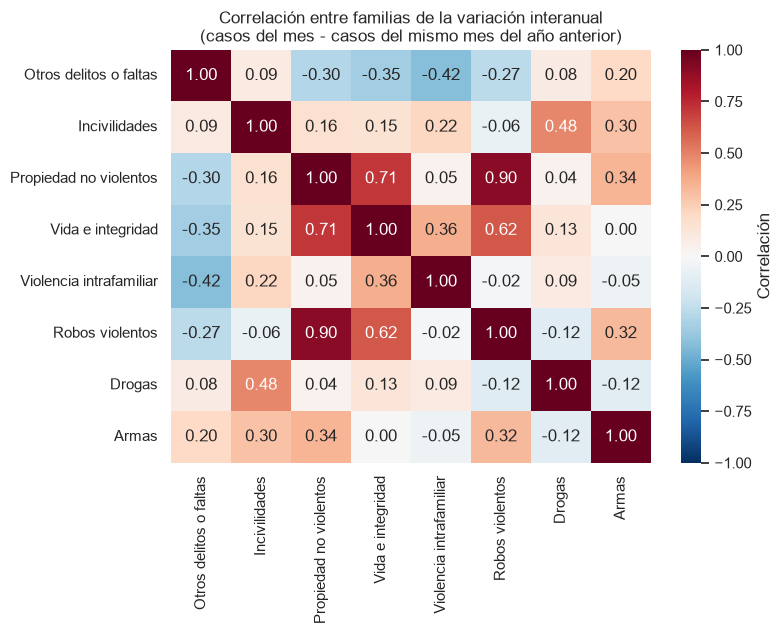

In [2]:
serie = fam.pivot_table(index='fecha', columns='Familia', values='casos')
var_anual = (serie - serie.shift(12)).dropna()
orden = serie.sum().sort_values(ascending=False).index
corr = var_anual[orden].corr()

fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, ax=ax,
            cbar_kws={'label': 'Correlación'})
ax.set_title('Correlación entre familias de la variación interanual\n(casos del mes - casos del mismo mes del año anterior)')
ax.set_xlabel(''); ax.set_ylabel('')
plt.tight_layout(); plt.savefig(FIG + 'a3_eda_correlacion.png', dpi=200); plt.show()

**Interpretación:** sin la estacionalidad, las familias tienden a moverse juntas, no en sentidos opuestos. Propiedad no violentos y Robos violentos tienen correlación 0,90 y Propiedad con Vida e integridad 0,71. Los movimientos opuestos son débiles: el más fuerte es Otros delitos frente a Violencia intrafamiliar (-0,42). Por eso cada familia se predice con sus propios meses anteriores y no con lo que hacen las otras familias en el mismo mes, que además no se conocería al momento de predecir.

## 2. Modelos y validación

Los dos modelos reciben las mismas entradas y el mismo preprocesamiento (one-hot de familia y escalado de las numéricas), ajustado solo con entrenamiento dentro de un `Pipeline`. Los hiperparámetros se eligen con validación cruzada temporal de 5 particiones por meses completos, las mismas para ambos modelos (MAE del índice). La prueba no se usa para elegir nada.

In [3]:
folds = m.folds_temporales(train, n_splits=5)
for i, (tr, va) in enumerate(folds, 1):
    print(f'Partición {i}: entrena hasta {train.fecha.iloc[tr].max():%Y-%m}, valida {train.fecha.iloc[va].min():%Y-%m} a {train.fecha.iloc[va].max():%Y-%m}')

X_tr, y_tr = train[m.FEATURES], train[m.OBJETIVO]
X_te = test[m.FEATURES]

busquedas = {
    'Ridge': GridSearchCV(m.modelo_ridge(), {'modelo__alpha': [0.1, 1, 10, 100]},
                          cv=folds, scoring='neg_mean_absolute_error'),
    'Random Forest': GridSearchCV(m.modelo_rf(), {'modelo__max_depth': [4, 8, None],
                                                  'modelo__min_samples_leaf': [1, 3, 5]},
                                  cv=folds, scoring='neg_mean_absolute_error'),
}
cv_res = {}
for nombre, gs in busquedas.items():
    gs.fit(X_tr, y_tr)
    i = gs.best_index_
    cv_res[nombre] = (-gs.cv_results_['mean_test_score'][i], gs.cv_results_['std_test_score'][i])
    print(f'{nombre:14} mejores parámetros: {gs.best_params_} | MAE CV del índice = {cv_res[nombre][0]:.3f} ± {cv_res[nombre][1]:.3f}')

Partición 1: entrena hasta 2020-10, valida 2020-11 a 2021-08
Partición 2: entrena hasta 2021-08, valida 2021-09 a 2022-06
Partición 3: entrena hasta 2022-06, valida 2022-07 a 2023-04
Partición 4: entrena hasta 2023-04, valida 2023-05 a 2024-02
Partición 5: entrena hasta 2024-02, valida 2024-03 a 2024-12
Ridge          mejores parámetros: {'modelo__alpha': 10} | MAE CV del índice = 0.124 ± 0.023
Random Forest  mejores parámetros: {'modelo__max_depth': 8, 'modelo__min_samples_leaf': 5} | MAE CV del índice = 0.121 ± 0.027


## 3. Rendimiento comparado

Métricas en casos, en entrenamiento y prueba. Unidades de MAE y RMSE: casos policiales por mes. La referencia ingenua predice el mismo valor del mismo mes del año anterior.

In [4]:
modelos = {n: gs.best_estimator_ for n, gs in busquedas.items()}
pred_tr = {n: m.a_casos(mod, train) for n, mod in modelos.items()}
pred_te = {n: m.a_casos(mod, test) for n, mod in modelos.items()}
pred_tr['Referencia (año anterior)'] = train['casos_mismo_mes_anio_ant'].values
pred_te['Referencia (año anterior)'] = test['casos_mismo_mes_anio_ant'].values

filas = []
for n in pred_te:
    mt, mp = m.metricas(train.casos, pred_tr[n]), m.metricas(test.casos, pred_te[n])
    filas.append({'Modelo': n, 'MAE train': mt['MAE'], 'MAE test': mp['MAE'],
                  'RMSE train': mt['RMSE'], 'RMSE test': mp['RMSE'],
                  'R2 train': mt['R2'], 'R2 test': mp['R2']})
tabla = pd.DataFrame(filas).set_index('Modelo')
tabla

,MAE train,MAE test,RMSE train,RMSE test,R2 train,R2 test
Modelo,,,,,,
Ridge,176.16,170.11,332.60,276.49,0.97,0.99
Random Forest,121.31,145.50,244.78,253.69,0.98,0.99
Referencia (año anterior),407.37,227.72,776.57,502.32,0.81,0.95


In [5]:
# MAE por familia en prueba, como % del promedio mensual de esa familia
prom = test.groupby('Familia')['casos'].mean()
orden_fam = prom.sort_values(ascending=False).index
mae_fam = pd.DataFrame({n: (test.assign(e=(test.casos - pred_te[n]).abs())
                            .groupby('Familia')['e'].mean() / prom * 100)
                        for n in pred_te}).loc[orden_fam]
mae_fam.round(1)

,Ridge,Random Forest,Referencia (año anterior)
Familia,,,
Otros delitos o faltas,6.30,5.70,12.90
Propiedad no violentos,6.60,5.50,6.50
Incivilidades,9.30,8.20,10.60
Vida e integridad,7.80,5.90,4.20
Violencia intrafamiliar,6.80,4.10,3.80
Robos violentos,11.40,9.40,16.10
Armas,20.10,23.00,27.80
Drogas,14.70,13.20,15.20


**Interpretación:**

- La validación cruzada elige el **Random Forest** (MAE del índice 0,121 ± 0,027 frente a 0,124 ± 0,023 de Ridge). Las dos medias están dentro de la dispersión, así que en validación quedan casi empatados.
- En prueba, el Random Forest se equivoca en promedio **145 casos al mes**, frente a 170 de Ridge y 228 de la referencia. Supera a la referencia por un 36%, así que cumple el criterio de éxito.
- El R² de prueba es 0,99 en ambos modelos e incluso 0,95 en la referencia. Está inflado porque las familias tienen escalas muy distintas: basta con acertar el orden de magnitud de cada familia para que el R² sea alto. Por eso priorizamos el MAE.
- Sobreajuste: el Random Forest baja de 121 casos de MAE en entrenamiento a 145 en prueba. Hay algo de sobreajuste, pero moderado (max_depth 8 y min_samples_leaf 5 lo limitan). Ridge tiene casi el mismo error en entrenamiento y prueba, pero más alto: le falta flexibilidad.
- Por familia, el error relativo es bajo en las grandes (entre 4% y 6% en Otros delitos, Propiedad, Vida e integridad y Violencia intrafamiliar, en el Random Forest) y alto en las chicas (Armas 23%, Drogas 13%). En las familias chicas un cambio de pocas decenas de casos ya pesa mucho.

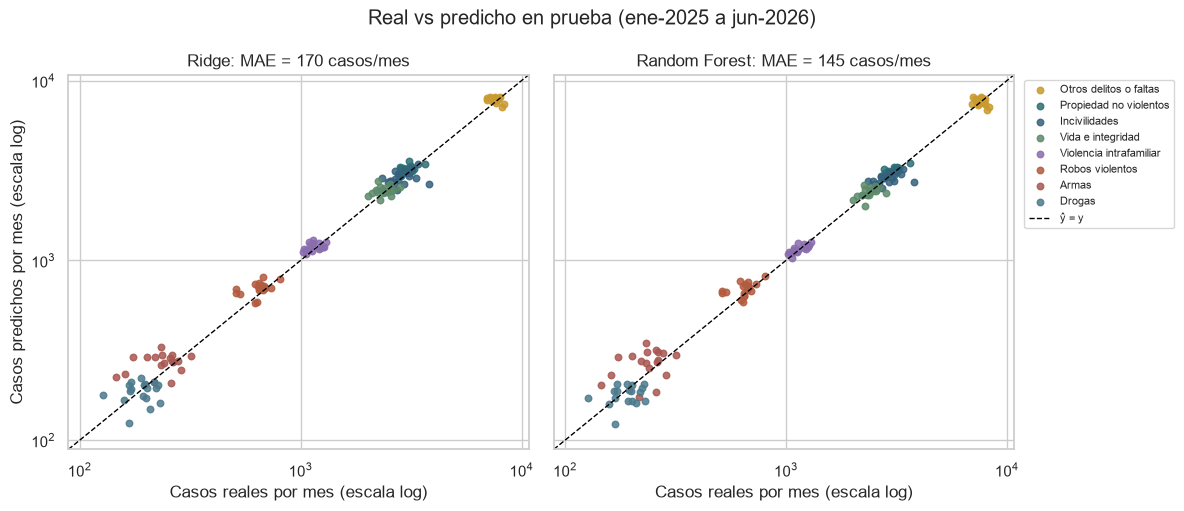

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5.2), sharex=True, sharey=True)
lim = [test.casos.min() * 0.7, test.casos.max() * 1.3]
for ax, n in zip(axes, ['Ridge', 'Random Forest']):
    for f in orden_fam:
        g = test[test.Familia == f]
        ax.scatter(g.casos, pred_te[n][g.index], s=22, color=COLORES.get(f, 'grey'), label=f, alpha=0.85)
    ax.plot(lim, lim, color='black', lw=1, ls='--', label='ŷ = y')
    ax.set_xscale('log'); ax.set_yscale('log'); ax.set_xlim(lim); ax.set_ylim(lim)
    ax.set_title(f'{n}: MAE = {miles(m.metricas(test.casos, pred_te[n])["MAE"])} casos/mes')
    ax.set_xlabel('Casos reales por mes (escala log)')
axes[0].set_ylabel('Casos predichos por mes (escala log)')
axes[1].legend(fontsize=8, loc='upper left', bbox_to_anchor=(1.01, 1))
fig.suptitle('Real vs predicho en prueba (ene-2025 a jun-2026)')
plt.tight_layout(); plt.savefig(FIG + 'a3_real_vs_pred.png', dpi=200, bbox_inches='tight'); plt.show()

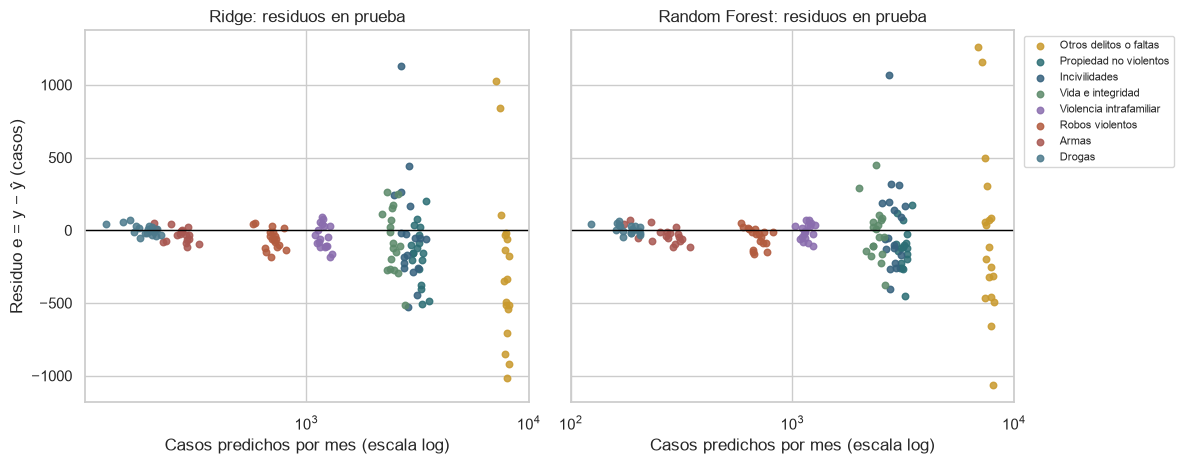

Ridge          mayor error: Incivilidades 2025-01 | real 3.795 | predicho 2.669 | error 1.126
               sesgo medio en prueba: -80 casos/mes
Random Forest  mayor error: Otros delitos o faltas 2025-01 | real 8.144 | predicho 6.886 | error 1.258
               sesgo medio en prueba: -29 casos/mes


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharey=True)
for ax, n in zip(axes, ['Ridge', 'Random Forest']):
    for f in orden_fam:
        g = test[test.Familia == f]
        p = pred_te[n][g.index]
        ax.scatter(p, g.casos - p, s=22, color=COLORES.get(f, 'grey'), label=f, alpha=0.85)
    ax.axhline(0, color='black', lw=1)
    ax.set_xscale('log')
    ax.set_title(f'{n}: residuos en prueba')
    ax.set_xlabel('Casos predichos por mes (escala log)')
axes[0].set_ylabel('Residuo e = y − ŷ (casos)')
axes[1].legend(fontsize=8, loc='upper left', bbox_to_anchor=(1.01, 1))
plt.tight_layout(); plt.savefig(FIG + 'a3_residuos.png', dpi=200, bbox_inches='tight'); plt.show()

for n in ['Ridge', 'Random Forest']:
    e = test.casos - pred_te[n]
    i = e.abs().idxmax()
    r = test.loc[i]
    print(f'{n:14} mayor error: {r.Familia} {r.fecha:%Y-%m} | real {miles(r.casos)} | predicho {miles(pred_te[n][i])} | error {miles(e[i])}')
    print(f'{"":14} sesgo medio en prueba: {e.mean():,.0f} casos/mes')

**Interpretación:**

- En real vs predicho, los dos modelos siguen la diagonal. La dispersión crece en las familias chicas (Armas y Drogas), donde el Random Forest tiende a sobreestimar Armas.
- Los residuos se abren a medida que crece la familia (heterocedasticidad): en casos absolutos, los errores grandes están en Otros delitos e Incivilidades. Ridge tiene un sesgo de -80 casos por mes (sobreestima en promedio) y el Random Forest -29, más cerca de cero.
- Error relevante: Otros delitos o faltas en enero de 2025. Hubo 8.144 casos y el Random Forest predijo 6.886 (1.258 de error, 15%). Ese mes tuvo un alza fuera de lo común y el modelo no la anticipó.

## 4. ¿Qué familias aumentan respecto al año anterior?

A partir de la predicción se responde la segunda parte de la pregunta: si la predicción del mes supera los casos del mismo mes del año anterior, el modelo anticipa un aumento. Lo comparamos con lo que pasó realmente.

In [8]:
base = test['casos_mismo_mes_anio_ant']
real_sube = test['casos'] > base
print(f'Prevalencia de aumentos reales en prueba: {real_sube.mean():.0%}')
for n in ['Ridge', 'Random Forest']:
    print(f'{n:14} acierta la dirección (sube / no sube) en {((pred_te[n] > base) == real_sube).mean():.0%} de los casos')

Prevalencia de aumentos reales en prueba: 55%
Ridge          acierta la dirección (sube / no sube) en 73% de los casos
Random Forest  acierta la dirección (sube / no sube) en 77% de los casos


In [9]:
mejor = min(['Ridge', 'Random Forest'], key=lambda n: cv_res[n][0])
print('Modelo elegido por validación cruzada:', mejor)
t = test.assign(sube_pred=pred_te[mejor] > base, sube_real=real_sube)
t['acierta'] = t.sube_pred == t.sube_real
resumen = (t.groupby('Familia')
             .agg(sube_real=('sube_real', 'sum'), sube_pred=('sube_pred', 'sum'), acierto=('acierta', 'mean'))
             .loc[orden_fam])
resumen['acierto'] = (resumen.acierto * 100).round(0)
resumen

Modelo elegido por validación cruzada: Random Forest


,sube_real,sube_pred,acierto
Familia,,,
Otros delitos o faltas,11,13,89.00
Propiedad no violentos,5,7,67.00
Incivilidades,12,14,78.00
Vida e integridad,12,12,67.00
Violencia intrafamiliar,16,16,78.00
Robos violentos,3,6,83.00
Armas,7,11,78.00
Drogas,13,11,78.00


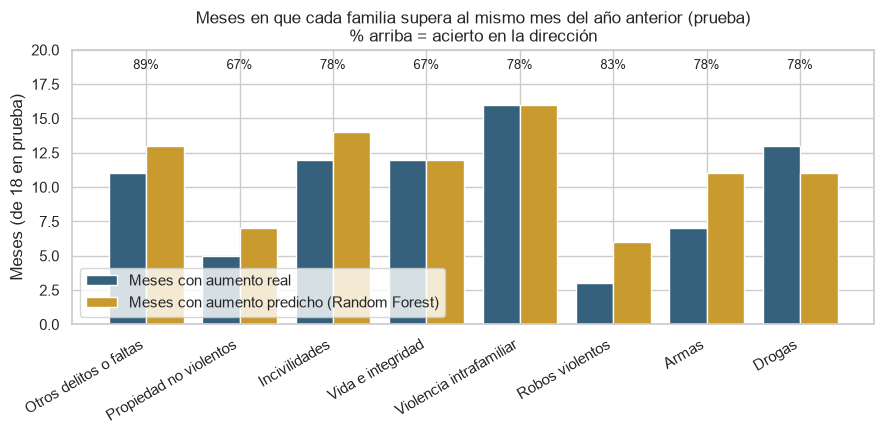

In [10]:
fig, ax = plt.subplots(figsize=(9, 4.5))
x = np.arange(len(resumen))
ax.bar(x - 0.2, resumen.sube_real, width=0.4, color='#35617D', label='Meses con aumento real')
ax.bar(x + 0.2, resumen.sube_pred, width=0.4, color='#C99A2E', label=f'Meses con aumento predicho ({mejor})')
for xi, a in zip(x, resumen.acierto):
    ax.text(xi, 18.6, f'{a:.0f}%', ha='center', fontsize=9)
ax.set_ylim(0, 20)
ax.set_xticks(x); ax.set_xticklabels(resumen.index, rotation=30, ha='right')
ax.set_ylabel('Meses (de 18 en prueba)')
ax.set_title('Meses en que cada familia supera al mismo mes del año anterior (prueba)\n% arriba = acierto en la dirección')
ax.legend(loc='lower left'); plt.tight_layout(); plt.savefig(FIG + 'a3_aumentos.png', dpi=200); plt.show()

**Interpretación:** en prueba, el 55% de los meses-familia sube respecto al mismo mes del año anterior. El Random Forest acierta la dirección en el 77% de los casos y Ridge en el 73%, bastante sobre el 55% que se obtendría diciendo siempre "sube". Por familia, acierta más en Otros delitos (89%) y Robos violentos (83%), y menos en Propiedad no violentos y Vida e integridad (67%). En Violencia intrafamiliar el modelo anticipa correctamente que sube casi todos los meses (16 de 18).

## 5. Explicabilidad global (SHAP)

Explicamos el modelo elegido. La salida explicada es el **índice relativo** predicho (1,0 = mes típico de esa familia en los últimos 12 meses), y la muestra son las 144 filas de prueba. Para leer mejor el gráfico, el seno y coseno del mes se suman en "Mes del año" y las columnas de familia en "Familia".

c:\Users\juanf\Documents\UNI\visualizacion\proyecto-viz-delitos\.venv\Lib\site-packages\numpy\lib\_nanfunctions_impl.py:1396: RuntimeWarning: All-NaN slice encountered
  return _nanquantile_unchecked(


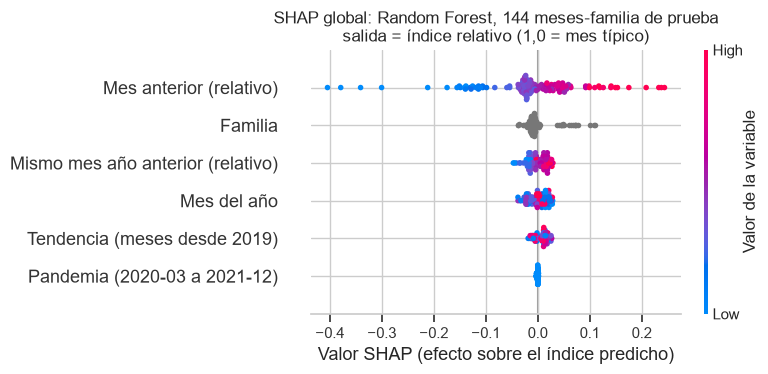

Mes anterior (relativo)             0.07
Familia                             0.02
Mismo mes año anterior (relativo)   0.01
Mes del año                         0.01
Tendencia (meses desde 2019)        0.01
Pandemia (2020-03 a 2021-12)        0.00
dtype: float64

In [11]:
pipe = modelos[mejor]
Xt_tr = pipe.named_steps['prep'].transform(X_tr)
Xt_te = pipe.named_steps['prep'].transform(X_te)
cols = list(pipe.named_steps['prep'].get_feature_names_out())
if mejor == 'Random Forest':
    explainer = shap.TreeExplainer(pipe.named_steps['modelo'])
else:
    explainer = shap.LinearExplainer(pipe.named_steps['modelo'], Xt_tr)
sv_raw = explainer(pd.DataFrame(Xt_te, columns=cols))

valores, color, texto, nombres = m.agrupar_shap(sv_raw, pipe, test)
sv = shap.Explanation(values=valores, base_values=sv_raw.base_values, data=color,
                      display_data=texto, feature_names=nombres)

plt.figure()
shap.plots.beeswarm(sv, show=False, color_bar_label='Valor de la variable')
plt.title(f'SHAP global: {mejor}, 144 meses-familia de prueba\nsalida = índice relativo (1,0 = mes típico)')
plt.xlabel('Valor SHAP (efecto sobre el índice predicho)')
plt.tight_layout(); plt.savefig(FIG + 'a3_shap_global.png', dpi=200, bbox_inches='tight'); plt.show()

pd.Series(np.abs(valores).mean(0), index=nombres).sort_values(ascending=False).round(3)

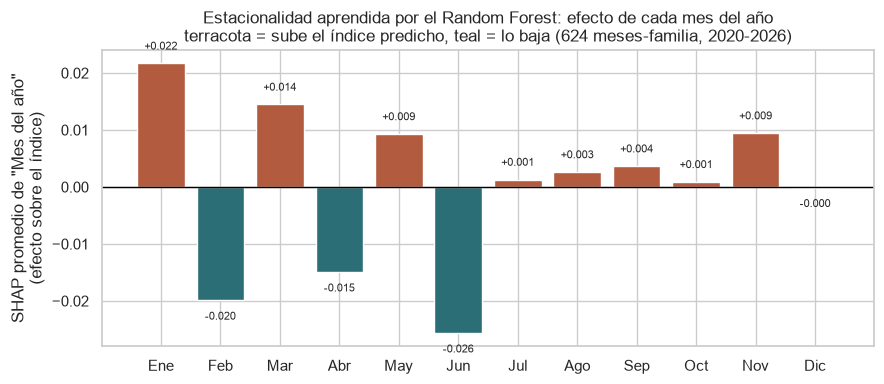

Ene    0.02
Feb   -0.02
Mar    0.01
Abr   -0.01
May    0.01
Jun   -0.03
Jul    0.00
Ago    0.00
Sep    0.00
Oct    0.00
Nov    0.01
Dic   -0.00
dtype: float64

In [12]:
# Efecto del mes del año: SHAP promedio de "Mes del año" para cada mes.
# Se calcula sobre las 624 filas (entrenamiento + prueba) para que cada mes tenga varios años.
todo = pd.concat([train, test], ignore_index=True)
sv_todo = explainer(pd.DataFrame(pipe.named_steps['prep'].transform(todo[m.FEATURES]), columns=cols))
val_todo, _, _, _ = m.agrupar_shap(sv_todo, pipe, todo)
ef_mes = pd.Series(val_todo[:, nombres.index('Mes del año')]).groupby(todo['mes'].values).mean()
ef_mes.index = viz.MESES

fig, ax = plt.subplots(figsize=(9, 4))
colores_mes = ['#B25B3E' if v > 0 else '#2C6E75' for v in ef_mes]
ax.bar(ef_mes.index, ef_mes.values, color=colores_mes)
ax.axhline(0, color='black', lw=1)
for i, v in enumerate(ef_mes.values):
    ax.text(i, v + (0.002 if v > 0 else -0.002), f'{v:+.3f}', ha='center',
            va='bottom' if v > 0 else 'top', fontsize=8)
ax.set_ylabel('SHAP promedio de "Mes del año"\n(efecto sobre el índice)')
ax.set_title(f'Estacionalidad aprendida por el {mejor}: efecto de cada mes del año\n'
             'terracota = sube el índice predicho, teal = lo baja (624 meses-familia, 2020-2026)')
plt.tight_layout(); plt.savefig(FIG + 'a3_efecto_mes.png', dpi=200); plt.show()
ef_mes.round(3)

**Interpretación (SHAP global, Random Forest):**

- La variable que más pesa es el **mes anterior en relación con el promedio de 12 meses**. Si el mes anterior estuvo sobre lo normal (rojo), el modelo sube el índice predicho, y si estuvo bajo (azul), lo baja. Es una inercia de corto plazo.
- Le siguen la **familia**, el **mismo mes del año anterior** y el **mes del año**.
- **Estacionalidad aprendida (gráfico de efecto por mes):** enero es el mes que más sube el índice (+0,022) y junio el que más lo baja (-0,026). Es la misma alza de verano y baja de invierno que vimos en el heatmap del EDA, aunque pesa menos que la inercia del mes anterior. Ojo con febrero (-0,020) y abril (-0,015): entre enero y junio, los meses de 31 días suben y los de 28 o 30 bajan. Parte de esta "estacionalidad" es simplemente que hay menos días para registrar casos.
- La pandemia casi no aporta en prueba, lo esperable porque 2025-2026 no está en pandemia.
- Limitación: SHAP describe cómo usa el modelo las variables, no causas. Además, el mes anterior y el mismo mes del año anterior están correlacionados, así que el modelo puede repartir su efecto entre ambos.

## 6. Explicaciones locales

Dos casos de prueba: un acierto (el de menor error relativo entre las tres familias más grandes) y el error más alto en casos.

In [13]:
pred = pd.Series(pred_te[mejor], index=test.index)
err = test.casos - pred
err_rel = err.abs() / test.casos
grandes = orden_fam[:3]
casos = {'Acierto': err_rel[test.Familia.isin(grandes)].idxmin(), 'Error alto': err.abs().idxmax()}
for etiqueta, i in casos.items():
    r = test.loc[i]
    print(f'{etiqueta:10} {r.Familia} {r.fecha:%Y-%m} | promedio 12 meses previos {miles(r.base_12m)} | '
          f'índice real {r.indice:.3f}, predicho {pred[i] / r.base_12m:.3f} | casos real {miles(r.casos)}, '
          f'predicho {miles(pred[i])} | error {miles(err[i])} ({err_rel[i]:.1%})')

Acierto    Otros delitos o faltas 2025-06 | promedio 12 meses previos 7.464 | índice real 1.007, predicho 1.002 | casos real 7.517, predicho 7.481 | error 36 (0.5%)
Error alto Otros delitos o faltas 2025-01 | promedio 12 meses previos 6.487 | índice real 1.255, predicho 1.062 | casos real 8.144, predicho 6.886 | error 1.258 (15.4%)


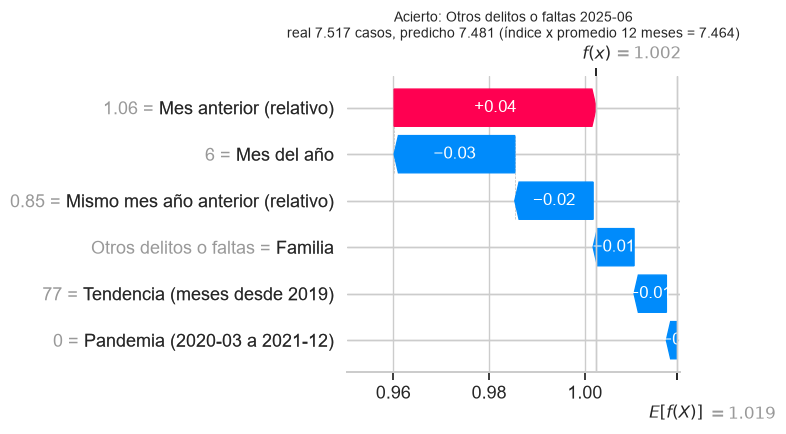

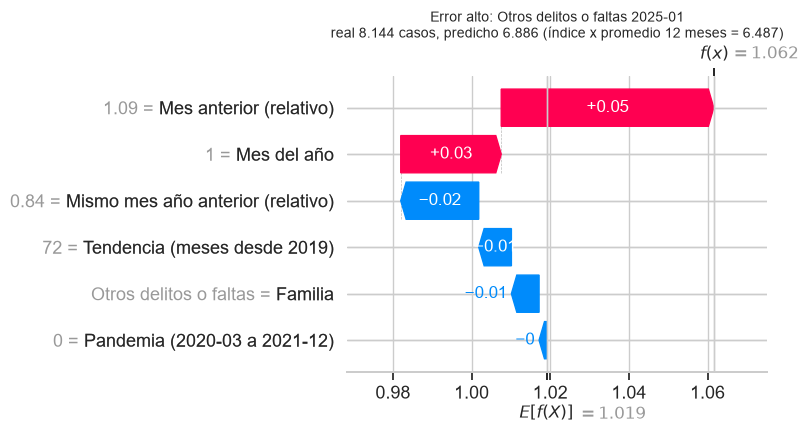

In [14]:
for etiqueta, i in casos.items():
    r = test.loc[i]
    plt.figure()
    shap.plots.waterfall(sv[i], show=False)
    plt.title(f'{etiqueta}: {r.Familia} {r.fecha:%Y-%m}\nreal {miles(r.casos)} casos, predicho {miles(pred[i])} '
              f'(índice x promedio 12 meses = {miles(r.base_12m)})', fontsize=10)
    plt.tight_layout()
    plt.savefig(FIG + f'a3_shap_{"acierto" if etiqueta == "Acierto" else "error"}.png', dpi=200, bbox_inches='tight')
    plt.show()

**Interpretación de los casos locales:** los dos casos son de Otros delitos o faltas, la familia más grande, en meses distintos.

- **Acierto (junio 2025):** real 7.517, predicho 7.481. El mes anterior estuvo sobre lo normal (1,06) y empuja el índice hacia arriba (+0,04), pero junio es un mes bajo (-0,03) y el mismo mes del año anterior fue bajo (0,85, -0,02). Los efectos se compensan y el índice queda en 1,00, justo lo que pasó.
- **Error alto (enero 2025):** real 8.144, predicho 6.886. El modelo sí sube el índice por el mes anterior alto (+0,05) y por ser enero (+0,03), pero enero de 2024 había sido bajo (0,84) y eso lo frena (-0,02). El índice real fue 1,26, un salto que no se parecía a ningún enero anterior (los anteriores estuvieron entre 0,93 y 1,07).
- **Contraste:** en ambos casos las mismas variables empujan en la misma dirección. La diferencia es que en enero de 2025 pasó algo fuera del patrón histórico, y un modelo basado solo en la historia de casos no lo puede anticipar.

## 7. Conclusión

- **Modelo recomendado: Random Forest.** Lo elige la validación cruzada, tiene el menor MAE en prueba (145 casos al mes frente a 170 de Ridge y 228 de la referencia), un sesgo más cercano a cero y acierta la dirección del cambio en el 77% de los casos.
- **Lo que aprende el modelo:** sobre todo la inercia de corto plazo (el mes anterior) y, en menor medida, la estacionalidad (enero alto, junio bajo), lo que coincide con el EDA.
- **Limitación principal:** no anticipa saltos fuera del patrón histórico, como Otros delitos en enero de 2025, y en las familias chicas el error relativo es alto (Armas 23%). Además, son solo 60 meses de entrenamiento y datos regionales.
- **Siguiente mejora:** modelar casos por día (para separar el efecto de los días del mes de la estacionalidad real), sumar variables de calendario (feriados, vacaciones, eventos) o datos comunales, y evaluar un modelo por familia para las familias chicas.